Name:Mehtab Ahmed
Student ID:023-24-0285
Section: H
Github:https://github.com/mehtabahmeddev/MACHINE-LEARNING
Dataset:Stroke Prediction (kaggle)

In [2]:
#part 0

#task1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import *
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier


In [3]:
#task2
df = pd.read_csv("healthcare-dataset-stroke-data_1.csv")

print(df.shape)

print(df.isnull().sum())

print(df["gender"].value_counts())

print(df["stroke"].value_counts())

print(df["stroke"].value_counts(normalize=True) * 100)

(5110, 12)
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


In [4]:
#task3
df = df.drop(columns=["id"])
X = df.drop(columns=["stroke"])
y = df["stroke"]

X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

In [5]:
#task4
SEED=42
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

X_train = X_train.copy()
X_test = X_test.copy()

median_bmi = X_train["bmi"].median()

X_train["bmi"] = X_train["bmi"].fillna(median_bmi)
X_test["bmi"] = X_test["bmi"].fillna(median_bmi)

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [10]:
#TASK5
print("total records : ",len(df))
print("Training stroke cases:", y_train.sum())

print("Testing stroke cases:", y_test.sum())

total records :  5110
Training stroke cases: 199
Testing stroke cases: 50


Q1:
ANSWER:DATA IS IMBALANCED BECAUSE STROKE HAS HIGHER VALUES THEN NON STROKE, STARTIFY=Y MAINTAIN PROPOTION BETWEEN THOSE IMBALANED DATA

PART 1:THE ACCURACY TRAP

In [11]:
#TASK1
dummy = DummyClassifier(
    strategy="most_frequent"
)

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)

print("Baseline Accuracy:", accuracy_score(y_test, dummy_pred))

Baseline Accuracy: 0.9510763209393346


In [18]:
#TASK2
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_s, y_train)

lr_pred = lr.predict(X_test_s)

lr_prob = lr.predict_proba(X_test_s)[:, 1]

print("Accuracy:", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred, zero_division=0))
print("Recall:", recall_score(y_test, lr_pred, zero_division=0))
print("F1:", f1_score(y_test, lr_pred, zero_division=0))
print("ROC AUC:", roc_auc_score(y_test, lr_prob))
print("PR AUC:", average_precision_score(y_test, lr_prob))
print(confusion_matrix(y_test, lr_pred))

Accuracy: 0.952054794520548
Precision: 1.0
Recall: 0.02
F1: 0.0392156862745098
ROC AUC: 0.8422016460905349
PR AUC: 0.27045630313141245
[[972   0]
 [ 49   1]]


In [19]:
#TASK3
def evaluate(model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    prob = model.predict_proba(X_test)[:, 1]

    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, prob),
        "PR AUC": average_precision_score(y_test, prob)
    }
    



PART2:UNDERFITTING,OVERFITTING,BIAS AND VARIANCE

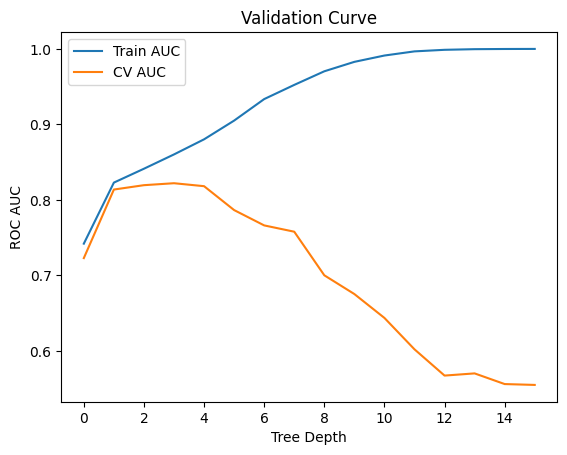

Best Depth: 4
Best CV AUC: 0.8220780766571256


In [20]:
#2.1 VALIDAITION CURVE

from sklearn.model_selection import validation_curve, StratifiedKFold

depths = list(range(1, 16)) + [None]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_scores, cv_scores = validation_curve(
    DecisionTreeClassifier(random_state=SEED),
    X_train,
    y_train,
    param_name="max_depth",
    param_range=depths,
    cv=cv,
    scoring="roc_auc"
)

train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)

plt.plot(range(len(depths)), train_mean, label="Train AUC")
plt.plot(range(len(depths)), cv_mean, label="CV AUC")

plt.xlabel("Tree Depth")
plt.ylabel("ROC AUC")
plt.title("Validation Curve")
plt.legend()
plt.show()

best_index = np.argmax(cv_mean)

print("Best Depth:", depths[best_index])
print("Best CV AUC:", cv_mean[best_index])


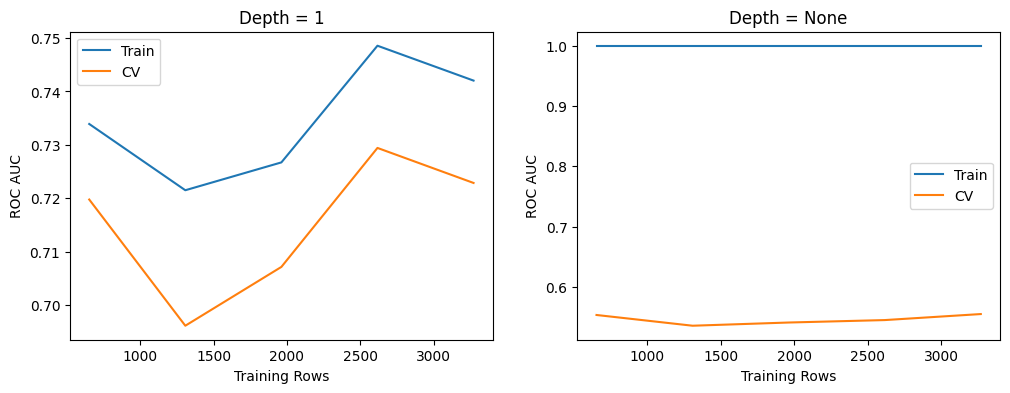

In [23]:
#2.2 lEARNING CURVES
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for depth, ax in zip([1, None], axes):

    sizes, train_scores, valid_scores = learning_curve(
        DecisionTreeClassifier(max_depth=depth, random_state=SEED),
        X_train,
        y_train,
        train_sizes=np.linspace(0.2, 1.0, 5),
        cv=cv,
        scoring="roc_auc"
    )

    ax.plot(sizes, train_scores.mean(axis=1), label="Train")
    ax.plot(sizes, valid_scores.mean(axis=1), label="CV")

    ax.set_title("Depth = " + str(depth))
    ax.set_xlabel("Training Rows")
    ax.set_ylabel("ROC AUC")
    ax.legend()

plt.show()

In [24]:
#2.3 VARIANCE MEASUREMENT
rng = np.random.default_rng(SEED)

variance_results = []

for depth in [1, 3, None]:

    all_probs = []
    auc_scores = []

    for i in range(40):

        idx = rng.choice(
            len(X_train),
            len(X_train),
            replace=True
        )

        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED + i
        )

        tree.fit(
            X_train.iloc[idx],
            y_train.iloc[idx]
        )

        prob = tree.predict_proba(X_test)[:, 1]

        all_probs.append(prob)

        auc_scores.append(
            roc_auc_score(y_test, prob)
        )

    all_probs = np.array(all_probs)

    avg_variance = all_probs.var(axis=0).mean()

    mean_auc = np.mean(auc_scores)

    avg_prediction_auc = roc_auc_score(
        y_test,
        all_probs.mean(axis=0)
    )

    variance_results.append({
        "Depth": depth,
        "Average Variance": avg_variance,
        "Mean Test AUC": mean_auc,
        "Average Prediction AUC": avg_prediction_auc
    })

variance_table = pd.DataFrame(variance_results)

print(variance_table)

   Depth  Average Variance  Mean Test AUC  Average Prediction AUC
0    1.0          0.000689       0.763430                0.813971
1    3.0          0.001787       0.795328                0.829434
2    NaN          0.039193       0.554632                0.764074


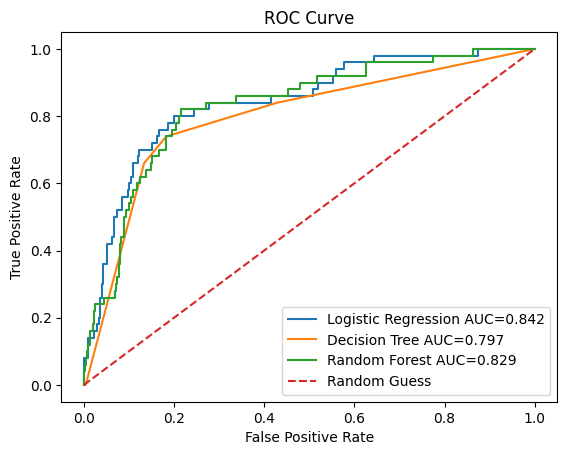

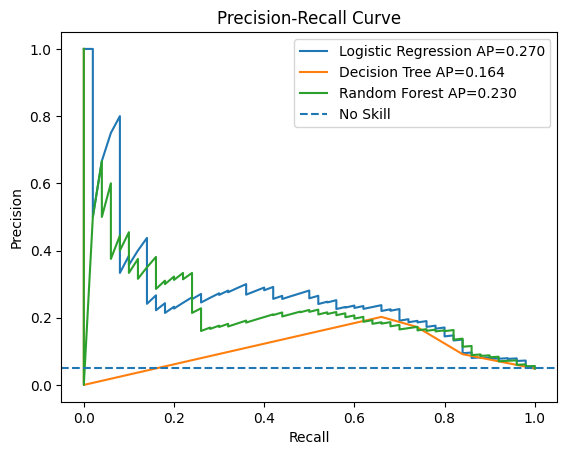

In [28]:
#PART3:  ROC, AUC, Precision-Recall and Thresholds
#3.1
lr_part3 = LogisticRegression(max_iter=1000)

dt_part3 = DecisionTreeClassifier(
    max_depth=3,
    random_state=SEED
)

rf_part3 = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)

lr_part3.fit(X_train_s, y_train)
dt_part3.fit(X_train, y_train)
rf_part3.fit(X_train, y_train)

#ROC curve
models = {
    "Logistic Regression": (lr_part3, X_test_s),
    "Decision Tree": (dt_part3, X_test),
    "Random Forest": (rf_part3, X_test)
}

for name, (model, test_data) in models.items():

    prob = model.predict_proba(test_data)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, prob)

    auc = roc_auc_score(y_test, prob)

    plt.plot(fpr, tpr, label=f"{name} AUC={auc:.3f}")

plt.plot([0, 1], [0, 1], "--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


for name, (model, test_data) in models.items():

    prob = model.predict_proba(test_data)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        prob
    )

    ap = average_precision_score(y_test, prob)

    plt.plot(recall, precision, label=f"{name} AP={ap:.3f}")

plt.axhline(y_test.mean(), linestyle="--", label="No Skill")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

In [29]:
#3.2 DECISION THREESHOLD
from sklearn.model_selection import cross_val_predict

oof_prob = cross_val_predict(
    LogisticRegression(max_iter=1000),
    X_train_s,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_prob
)

valid_thresholds = thresholds[recall[:-1] >= 0.80]

best_threshold = valid_thresholds.max()

print("Best Threshold:", best_threshold)

Best Threshold: 0.05003991821877207


In [30]:
test_lr_prob = lr_part3.predict_proba(X_test_s)[:, 1]

threshold_pred = (
    test_lr_prob >= best_threshold
).astype(int)

print("Recall:", recall_score(y_test, threshold_pred))
print("Precision:", precision_score(y_test, threshold_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, threshold_pred))

print("Flagged Patients:", threshold_pred.sum())

cm = confusion_matrix(y_test, threshold_pred)

print("False Alarms:", cm[0, 1])

Recall: 0.82
Precision: 0.13993174061433447
Confusion Matrix:
[[720 252]
 [  9  41]]
Flagged Patients: 293
False Alarms: 252


OC AUC high, recall low: AUC measures the model's overall ranking ability across different thresholds. Recall can still be low at the default 0.5 threshold.

ROC vs PR: For imbalanced data, the Precision-Recall curve is more informative because it focuses directly on the precision and recall of the positive class.

The price of higher recall: More patients will be flagged, which increases false alarms. The hospital needs to weigh missed stroke cases against unnecessary medical evaluations.

In [33]:
#PART4 UNDERSAMPLING,OVERSAMPLING AND SMOTE
#4.1
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
def make_model(name, balanced=False):

    if name == "Logistic Regression":

        return LogisticRegression(
            max_iter=1000,
            class_weight="balanced" if balanced else None
        )

    else:

        return RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=5,
            random_state=SEED,
            class_weight="balanced" if balanced else None
        )
results = []

for name in ["Logistic Regression", "Random Forest"]:

    if name == "Logistic Regression":
        Xtr = X_train_s
        Xte = X_test_s
    else:
        Xtr = X_train
        Xte = X_test

    for method in [
        "None",
        "Class Weight",
        "Undersampling",
        "Oversampling",
        "SMOTE"
    ]:

        model = make_model(
            name,
            balanced=(method == "Class Weight")
        )

        X_fit = Xtr
        y_fit = y_train

        if method == "Undersampling":

            X_fit, y_fit = RandomUnderSampler(
                random_state=SEED
            ).fit_resample(Xtr, y_train)

        elif method == "Oversampling":

            X_fit, y_fit = RandomOverSampler(
                random_state=SEED
            ).fit_resample(Xtr, y_train)

        elif method == "SMOTE":

            X_fit, y_fit = SMOTE(
                random_state=SEED
            ).fit_resample(Xtr, y_train)

        model.fit(X_fit, y_fit)

        prob = model.predict_proba(Xte)[:, 1]

        pred = (prob >= 0.5).astype(int)

        results.append({
            "Model": name,
            "Method": method,
            "Training Rows": len(y_fit),
            "Stroke Cases": int(y_fit.sum()),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, prob),
            "PR AUC": average_precision_score(y_test, prob)
        })

results_df = pd.DataFrame(results)

print(results_df)
        

C:\Users\SINDH\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\SINDH\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\SINDH\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\SINDH\AppData\Local\Programs\Python\Pytho

                 Model         Method  Training Rows  Stroke Cases  Precision  \
0  Logistic Regression           None           4088           199   1.000000   
1  Logistic Regression   Class Weight           4088           199   0.138408   
2  Logistic Regression  Undersampling            398           199   0.135314   
3  Logistic Regression   Oversampling           7778          3889   0.137457   
4  Logistic Regression          SMOTE           7778          3889   0.140351   
5        Random Forest           None           4088           199   0.000000   
6        Random Forest   Class Weight           4088           199   0.210526   
7        Random Forest  Undersampling            398           199   0.118497   
8        Random Forest   Oversampling           7778          3889   0.188406   
9        Random Forest          SMOTE           7778          3889   0.149254   

   Recall        F1   ROC AUC    PR AUC  
0    0.02  0.039216  0.842202  0.270456  
1    0.80  0.235988  0.8

In [35]:
#4.2 The classic mistake
X_all_bad = X.copy()

X_all_bad["bmi"] = X_all_bad["bmi"].fillna(
    X_all_bad["bmi"].median()
)

X_smote_all, y_smote_all = SMOTE(
    random_state=SEED
).fit_resample(X_all_bad, y)

X_train_bad, X_test_bad, y_train_bad, y_test_bad = train_test_split(
    X_smote_all,
    y_smote_all,
    test_size=0.2,
    random_state=SEED,
    stratify=y_smote_all
)
rf_bad = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)

rf_bad.fit(X_train_bad, y_train_bad)

bad_prob = rf_bad.predict_proba(X_test_bad)[:, 1]

bad_pred = rf_bad.predict(X_test_bad)

print("Precision:", precision_score(y_test_bad, bad_pred))
print("Recall:", recall_score(y_test_bad, bad_pred))
print("F1:", f1_score(y_test_bad, bad_pred))
print("ROC AUC:", roc_auc_score(y_test_bad, bad_prob))
print("PR AUC:", average_precision_score(y_test_bad, bad_prob))


Precision: 0.9309644670050762
Recall: 0.9434156378600823
F1: 0.9371486969851814
ROC AUC: 0.9856072813706707
PR AUC: 0.9852758169240167


In [36]:
correct = results_df[
    (results_df["Model"] == "Random Forest") &
    (results_df["Method"] == "SMOTE")
]

wrong = pd.DataFrame([{
    "Model": "Random Forest",
    "Method": "Wrong SMOTE",
    "Precision": precision_score(y_test_bad, bad_pred),
    "Recall": recall_score(y_test_bad, bad_pred),
    "F1": f1_score(y_test_bad, bad_pred),
    "ROC AUC": roc_auc_score(y_test_bad, bad_prob),
    "PR AUC": average_precision_score(y_test_bad, bad_prob)
}])

comparison = pd.concat([correct, wrong], ignore_index=True)

print(comparison)

           Model       Method  Training Rows  Stroke Cases  Precision  \
0  Random Forest        SMOTE         7778.0        3889.0   0.149254   
1  Random Forest  Wrong SMOTE            NaN           NaN   0.930964   

     Recall        F1   ROC AUC    PR AUC  
0  0.200000  0.170940  0.777469  0.125918  
1  0.943416  0.937149  0.985607  0.985276  


Logistic Regression: Resampling changes the class balance. Recall often increases while precision may decrease. Record the exact numerical difference using your specific metrics table.

Random Forest: Its response can differ from Logistic Regression because the two models learn patterns from data in fundamentally different ways.

Incorrect SMOTE Implementation: Test data was mistakenly included in the SMOTE process. This leaked test set information into model training, making the evaluated results unreliable and untrustworthy.

Selection Strategy for the Hospital: Select the method from your table that achieves a strong recall score while maintaining an acceptable level of false alarms for clinical operations.

In [39]:
#PART5 NOSIY DATA

#5.1
def flip_labels(y, fraction, seed):

    y_new = y.copy()

    rng = np.random.default_rng(seed)

    n = int(len(y_new) * fraction)

    idx = rng.choice(
        len(y_new),
        n,
        replace=False
    )

    y_new.iloc[idx] = 1 - y_new.iloc[idx]

    return y_new

def get_roc_auc(name, Xtr, ytr, Xte, yte):

    if name == "Logistic Regression":

        scaler_temp = StandardScaler()

        Xtr = scaler_temp.fit_transform(Xtr)
        Xte = scaler_temp.transform(Xte)

        model = LogisticRegression(max_iter=1000)

    elif name == "Decision Tree 3":

        model = DecisionTreeClassifier(
            max_depth=3,
            random_state=SEED
        )

    elif name == "Decision Tree None":

        model = DecisionTreeClassifier(
            random_state=SEED
        )

    else:

        model = RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=5,
            random_state=SEED
        )

    model.fit(Xtr, ytr)

    prob = model.predict_proba(Xte)[:, 1]

    return roc_auc_score(yte, prob)

In [40]:
model_names = [
    "Logistic Regression",
    "Decision Tree 3",
    "Decision Tree None",
    "Random Forest"
]

label_results = []

for fraction in [0, 0.05, 0.10, 0.20]:

    repeats = 1 if fraction == 0 else 5

    scores = {name: [] for name in model_names}

    for r in range(repeats):

        y_noisy = flip_labels(
            y_train,
            fraction,
            SEED + r
        )

        for name in model_names:

            score = get_roc_auc(
                name,
                X_train,
                y_noisy,
                X_test,
                y_test
            )

            scores[name].append(score)

    row = {"Noise Fraction": fraction}

    for name in model_names:
        row[name] = np.mean(scores[name])

    label_results.append(row)

label_df = pd.DataFrame(label_results)

print(label_df)

   Noise Fraction  Logistic Regression  Decision Tree 3  Decision Tree None  \
0            0.00             0.842202         0.796852            0.567881   
1            0.05             0.831967         0.797837            0.553428   
2            0.10             0.811683         0.789817            0.530646   
3            0.20             0.807177         0.769294            0.518395   

   Random Forest  
0       0.829095  
1       0.792654  
2       0.750115  
3       0.699379  


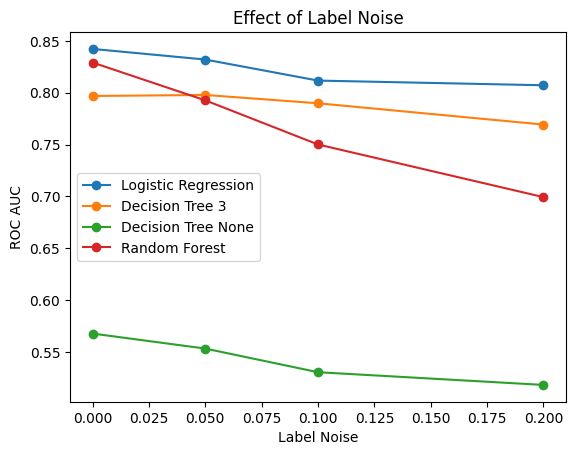

In [45]:
label_df.set_index("Noise Fraction").plot(
    marker="o"
)

plt.xlabel("Label Noise")
plt.ylabel("ROC AUC")
plt.title("Effect of Label Noise")
plt.show()

In [49]:
#5.2
def add_feature_noise(X, level, seed):

    noisy = X.copy()

    rng = np.random.default_rng(seed)

    for col in ["age", "avg_glucose_level", "bmi"]:

        noise = rng.normal(
            0,
            1,
            len(noisy)
        ) * noisy[col].std() * level

        noisy[col] = noisy[col] + noise

    return noisy

In [50]:
feature_results = []

for level in [0, 0.5, 1, 2]:

    scores = {name: [] for name in model_names}

    for r in range(5):

        X_noisy = add_feature_noise(
            X_train,
            level,
            SEED + r
        )

        for name in model_names:

            score = get_roc_auc(
                name,
                X_noisy,
                y_train,
                X_test,
                y_test
            )

            scores[name].append(score)

    row = {"Noise Level": level}

    for name in model_names:
        row[name] = np.mean(scores[name])

    feature_results.append(row)

feature_df = pd.DataFrame(feature_results)

print(feature_df)

   Noise Level  Logistic Regression  Decision Tree 3  Decision Tree None  \
0          0.0             0.842202         0.796852            0.567881   
1          0.5             0.838115         0.809202            0.524749   
2          1.0             0.814700         0.768193            0.524967   
3          2.0             0.772366         0.708379            0.531288   

   Random Forest  
0       0.829095  
1       0.815842  
2       0.784103  
3       0.752356  


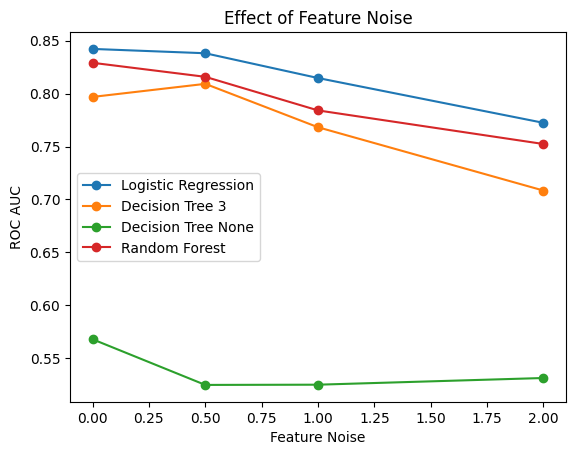

In [51]:
feature_df.set_index("Noise Level").plot(
    marker="o"
)

plt.xlabel("Feature Noise")
plt.ylabel("ROC AUC")
plt.title("Effect of Feature Noise")
plt.show()

In [52]:
#5.3 SMOTE AND NOisy labels
def smote_noise_result(name, y_noisy, use_smote, seed):

    if name == "Logistic Regression":

        scaler_temp = StandardScaler()

        Xtr = scaler_temp.fit_transform(X_train)
        Xte = scaler_temp.transform(X_test)

        model = LogisticRegression(max_iter=1000)

    else:

        Xtr = X_train
        Xte = X_test

        model = RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=5,
            random_state=SEED
        )

    X_fit = Xtr
    y_fit = y_noisy

    if use_smote:

        X_fit, y_fit = SMOTE(
            random_state=seed
        ).fit_resample(Xtr, y_noisy)

    model.fit(X_fit, y_fit)

    prob = model.predict_proba(Xte)[:, 1]

    return (
        roc_auc_score(y_test, prob),
        average_precision_score(y_test, prob)
    )

In [53]:
noise_smote_results = []

for r in range(3):

    y_noisy = flip_labels(
        y_train,
        0.10,
        SEED + r
    )

    for name in ["Logistic Regression", "Random Forest"]:

        for method in ["Without SMOTE", "With SMOTE"]:

            use_smote = method == "With SMOTE"

            roc, pr = smote_noise_result(
                name,
                y_noisy,
                use_smote,
                SEED + r
            )

            noise_smote_results.append({
                "Model": name,
                "Method": method,
                "ROC AUC": roc,
                "PR AUC": pr
            })

noise_smote_df = pd.DataFrame(noise_smote_results)

print(
    noise_smote_df.groupby(
        ["Model", "Method"]
    )[["ROC AUC", "PR AUC"]].mean()
)

                                    ROC AUC    PR AUC
Model               Method                           
Logistic Regression With SMOTE     0.806872  0.249173
                    Without SMOTE  0.812647  0.240601
Random Forest       With SMOTE     0.608800  0.062620
                    Without SMOTE  0.760110  0.160356


In [55]:
#FINAL DECISION AND CONCLUSION
default_pred = (
    test_lr_prob >= 0.5
).astype(int)

chosen_pred = (
    test_lr_prob >= best_threshold
).astype(int)
def final_result(name, pred):

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1]
    )

    return {
        "Threshold": name,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "False Alarms": cm[0, 1],
        "Missed Strokes": cm[1, 0]
    }

final_table = pd.DataFrame([
    final_result("Default 0.5", default_pred),
    final_result("Chosen Threshold", chosen_pred)
])

print(final_table)

          Threshold  Precision  Recall        F1  False Alarms  Missed Strokes
0       Default 0.5   1.000000    0.02  0.039216             0              49
1  Chosen Threshold   0.139932    0.82  0.239067           252               9


In [57]:
cm = confusion_matrix(
    y_test,
    chosen_pred,
    labels=[0, 1]
)

print("1. I selected Logistic Regression with a threshold of", best_threshold)

print("2. Precision:", precision_score(y_test, chosen_pred, zero_division=0))

print("3. Recall:", recall_score(y_test, chosen_pred))

print("4. F1 Score:", f1_score(y_test, chosen_pred, zero_division=0))

print("5. False alarms:", cm[0, 1])

print("6. Missed strokes:", cm[1, 0])

print("7. Leakage was avoided by fitting the median and scaler on training data only.")



1. I selected Logistic Regression with a threshold of 0.05003991821877207
2. Precision: 0.13993174061433447
3. Recall: 0.82
4. F1 Score: 0.239067055393586
5. False alarms: 252
6. Missed strokes: 9
7. Leakage was avoided by fitting the median and scaler on training data only.


Final Reflection
(a) Most surprising result:

A model can achieve high accuracy but still miss many stroke patients because the data is imbalanced.

(b) If I had one more hour:

I would test more thresholds and try to reduce false alarms while maintaining high recall.